# Hydraulic ram pump: reference solver and checks

This notebook is an **independent Python implementation** of the physics used by the web app (`src/physics.js`). It exists to answer one question: *are the numbers right?*

It does five things:

1. Re-implements the model from the equations in `docs/theory.md`.
2. Runs the default pump and plots what happens at the pump.
3. Checks the physics against closed-form results: the **water balance**, the **Joukowsky** pressure rise, the **steady-flow energy equation**, and **hoop stress / burst head**.
4. **Cross-checks** this solver against the JavaScript solver, step for step, using the files in `python/data/` written by `node tools/export-run.js`.
5. Runs a small design study (delivered flow and efficiency against lift).

Run the cells from top to bottom. Needs `numpy` and `matplotlib` only. All units are SI and heads are metres of water above the pump centreline.

In [1]:
import math, csv, pathlib
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
DATA = pathlib.Path("data")
print("numpy", np.__version__)

numpy 2.5.3


## 1. The model

| Part | Model |
|---|---|
| Drive pipe | Elastic water hammer, method of characteristics, steady Darcy friction |
| Supply valve | Series loss `K = 0.2 / opening²` between the pipe and the pump body |
| Waste (impulse) valve | Mass on a spring. Opening force = `preload × ρ g A_seat Hs`. Closing force = `ρ g H_body A_seat (1 + 2.5 A_gap/A_seat)` |
| Check valve | Orifice that passes water from the body to the air chamber only |
| Air chamber | Gas with `p V^1.2 = const` over a water volume |
| Delivery pipe | Rigid water column with a rising front, friction and an exit loss |
| Failure | Hoop stress `σ = ρ g H (D + t) / 2t` against tensile strength (checked in the JavaScript solver; here we check the formula) |

The port below follows the JavaScript line by line, without the failure branches.

In [2]:
G, RHO, K_WATER, PA, NPOLY = 9.81, 1000.0, 2.2e9, 101325.0, 1.2
CD_W, CD_C, KFLOW, H_MIN = 0.65, 0.7, 2.5, -9.5

MATERIALS = {   # E (Pa), Su = tensile strength (Pa), eps = roughness (m)
    "steel":     dict(E=200e9, Su=360e6, eps=0.15e-3),
    "ductile":   dict(E=170e9, Su=420e6, eps=0.25e-3),
    "castiron":  dict(E=100e9, Su=200e6, eps=0.25e-3),
    "copper":    dict(E=117e9, Su=220e6, eps=0.0015e-3),
    "bronze":    dict(E=105e9, Su=260e6, eps=0.0015e-3),
    "aluminium": dict(E=70e9,  Su=200e6, eps=0.0015e-3),
    "pvc":       dict(E=3e9,   Su=50e6,  eps=0.0015e-3),
    "hdpe":      dict(E=0.8e9, Su=22e6,  eps=0.007e-3),
}
DEFAULTS = dict(Hs=4, L=10, D=0.05, mat="steel", e=0.0035, ds=0.05, stroke=0.006, vmass=0.3, vratio=1.1,
                dc=0.025, Vch=0.004, Dch=0.1, pumpMat="castiron", tb=0.008, tch=0.006,
                Dd=0.025, Ld=50, h=18, dmat="hdpe", ed=0.0023, prefilled=False, valveTime=2.0)

def wave_speed(p):
    E = MATERIALS[p["mat"]]["E"]
    return math.sqrt(K_WATER / RHO) / math.sqrt(1 + K_WATER * p["D"] / (E * p["e"]))

def hoop(head, D, t):          # thin-wall cylinder, mean-diameter form
    return RHO * G * max(head, 0.0) * (D + t) / (2 * t)

def burst_head(mat, D, t):
    return 2 * t * MATERIALS[mat]["Su"] / (RHO * G * (D + t))

def fric(V, D, eps):
    Re = max(abs(V) * D / 1.0e-6, 100.0)
    if Re < 2000: return 64.0 / Re
    R = max(Re, 4000.0)
    t = math.log10(eps / (3.7 * D) + 5.74 / R ** 0.9)
    return 0.25 / (t * t)

print("wave speed, 50 mm steel pipe, 3.5 mm wall: %.1f m/s" % wave_speed(DEFAULTS))

wave speed, 50 mm steel pipe, 3.5 mm wall: 1378.9 m/s


In [3]:
class Ram:
    """One hydraulic ram pump. Call step() repeatedly with the supply valve target in phi_target."""
    def __init__(self, **kw):
        p = dict(DEFAULTS); p.update(kw); self.p = p
        self.eps = MATERIALS[p["mat"]]["eps"]; self.epsD = MATERIALS[p["dmat"]]["eps"]
        self.a = wave_speed(p); self.A = math.pi * p["D"] ** 2 / 4
        self.N = min(400, max(4, round(p["L"] / (self.a * 0.0015))))
        self.dt = p["L"] / (self.N * self.a); self.dx = p["L"] / self.N; self.B = self.a / (G * self.A)
        N = self.N
        self.H = [p["Hs"]] * (N + 1); self.Q = [0.0] * (N + 1)     # no leaks here, so one flow array
        self.phi = 0.0; self.phi_target = 0.0
        self.y = p["stroke"]; self.yd = 0.0; self.As = math.pi * p["ds"] ** 2 / 4; self.closing = False
        self.Hb = 0.0; self.Hpipe = p["Hs"]; self.Qw = 0.0; self.Qd = 0.0; self.Hch = 0.0
        self.Vg0 = p["Vch"]; self.Vg = p["Vch"]; self.Vw = 0.0; self.Vw0 = 0.0
        self.Ad = math.pi * p["Dd"] ** 2 / 4
        self.x0 = p["Ld"] if p["prefilled"] else 0.3; self.x = self.x0; self.vd = 0.0; self.Qtop = 0.0; self.lift = 0.0
        self.V = dict(intake=0.0, drive=0.0, waste=0.0, pump=0.0, delivered=0.0, clip=0.0)
        self.beats = 0; self.beat_times = []; self.t = 0.0; self.steps = 0
        if p["prefilled"]:
            self.Hch = p["h"]
            self.Vg = self.Vg0 * (PA / (PA + RHO * G * p["h"])) ** (1 / NPOLY)
            self.Vw = self.Vw0 = self.Vg0 - self.Vg

    def step(self):
        p, N, B, dt = self.p, self.N, self.B, self.dt
        H, Q = self.H, self.Q
        step_phi = dt / max(p["valveTime"], 1e-4)
        if self.phi < self.phi_target: self.phi = min(self.phi_target, self.phi + step_phi)
        elif self.phi > self.phi_target: self.phi = max(self.phi_target, self.phi - step_phi)
        vm = sum(abs(q) for q in Q) / (N + 1) / self.A
        R = fric(vm, p["D"], self.eps) * self.dx / (2 * G * p["D"] * self.A ** 2)
        Hn = [0.0] * (N + 1); Qn = [0.0] * (N + 1)
        for i in range(1, N):                                     # interior nodes
            CP = H[i-1] + B * Q[i-1]; CM = H[i+1] - B * Q[i+1]
            BP = B + R * abs(Q[i-1]); BM = B + R * abs(Q[i+1])
            q = (CP - CM) / (BP + BM); Qn[i] = q; Hn[i] = CP - BP * q
        CM = H[1] - B * Q[1]; BM = B + R * abs(Q[1])                # intake end, entrance loss 0.5
        kk = 0.5 / (2 * G * self.A ** 2); d = p["Hs"] - CM; ad = abs(d)
        q = math.copysign(1.0, d) * 2 * ad / (BM + math.sqrt(BM * BM + 4 * kk * ad)) if ad > 0 else 0.0
        Qn[0] = q; Hn[0] = CM + BM * q
        CP = H[N-1] + B * Q[N-1]; BP = B + R * abs(Q[N-1])         # pump end
        Aw = min(math.pi * p["ds"] * self.y, self.As)
        Cv = CD_W * Aw * math.sqrt(2 * G); Cc = CD_C * (math.pi * p["dc"] ** 2 / 4) * math.sqrt(2 * G)
        Hch = self.Hch
        if self.phi < 1e-3:
            Qn[N] = 0.0; Hn[N] = CP; self.Hb = 0.0; self.Qw = 0.0; self.Qd = 0.0; self.Hpipe = CP
        else:
            kvq = (0.2 / self.phi ** 2) / (2 * G * self.A ** 2)
            F = lambda hb: Cv * math.sqrt(max(hb, 0.0)) + (Cc * math.sqrt(hb - Hch) if hb > Hch else 0.0)
            def r(hb):
                q = F(hb); return CP - BP * q - kvq * q * q - hb
            lo, hi = H_MIN, max(CP, H_MIN + 1e-6)
            if r(lo) <= 0: hb = lo
            else:
                for _ in range(40):
                    m = 0.5 * (lo + hi)
                    if r(m) > 0: lo = m
                    else: hi = m
                hb = 0.5 * (lo + hi)
            q = F(hb); Qn[N] = q; Hn[N] = CP - BP * q; self.Hpipe = Hn[N]; self.Hb = hb
            self.Qw = Cv * math.sqrt(max(hb, 0.0)); self.Qd = Cc * math.sqrt(hb - Hch) if hb > Hch else 0.0
        self.H, self.Q = Hn, Qn
        V = self.V; V["intake"] += Qn[0] * dt; V["drive"] += Qn[N] * dt; V["waste"] += self.Qw * dt; V["pump"] += self.Qd * dt
        # waste flap
        m = p["vmass"]; Fopen = p["vratio"] * RHO * G * self.As * p["Hs"]
        Awf = min(math.pi * p["ds"] * self.y, self.As); kfac = 1 + KFLOW * (Awf / self.As)
        Fcl = RHO * G * self.Hb * self.As * kfac
        self.yd += dt * ((Fopen - Fcl) / m - 8 * self.yd); self.y += self.yd * dt
        if self.y >= p["stroke"]:
            self.y = p["stroke"]
            if self.yd > 0: self.yd = -0.25 * self.yd
        if self.y <= 0:
            self.y = 0.0; self.yd = 0.0
            if not self.closing:
                self.closing = True; self.beats += 1; self.beat_times.append(self.t)
        elif self.y > 0.2 * p["stroke"]: self.closing = False
        # delivery column and air chamber
        full = self.x >= p["Ld"]
        fd = fric(self.vd, p["Dd"], self.epsD); z = self.x * p["h"] / p["Ld"]
        hf = (fd * self.x / p["Dd"] + (1.0 if full else 0.5)) * self.vd * abs(self.vd) / (2 * G)
        vd = self.vd + dt * G * (self.Hch - z - hf) / max(self.x, 0.3)
        if full and vd < 0: vd = 0.0
        dxs = vd * dt
        if (not full) and self.x + dxs < 0.3: dxs = 0.3 - self.x
        lim = (self.Qd * dt + self.Vw) / self.Ad
        if dxs > lim: dxs = lim
        self.vd = dxs / dt
        if not full:
            if self.x + dxs >= p["Ld"]:
                over = self.x + dxs - p["Ld"]; self.x = p["Ld"]; V["delivered"] += over * self.Ad; self.Qtop = over * self.Ad / dt
            else: self.x += dxs; self.Qtop = 0.0
        else:
            V["delivered"] += max(dxs, 0.0) * self.Ad; self.Qtop = max(dxs, 0.0) * self.Ad / dt
        qout = dxs * self.Ad / dt
        Vw = self.Vw + (self.Qd - qout) * dt
        if Vw < 0: V["clip"] -= Vw; Vw = 0.0
        Vgmin = 0.002 * self.Vg0
        if self.Vg0 - Vw < Vgmin: V["clip"] += Vw - (self.Vg0 - Vgmin); Vw = self.Vg0 - Vgmin
        self.Vw = Vw; self.Vg = self.Vg0 - Vw
        self.Hch = (PA * (self.Vg0 / self.Vg) ** NPOLY - PA) / (RHO * G)
        self.t += dt; self.steps += 1

    def balance(self):
        V = self.V; stored = self.Vw - self.Vw0; column = (self.x - self.x0) * self.Ad
        return dict(intake=V["intake"], drive=V["drive"], waste=V["waste"], pump=V["pump"], stored=stored, column=column,
                    delivered=V["delivered"], clip=V["clip"],
                    res_body=V["drive"] - V["waste"] - V["pump"],
                    res_delivery=V["pump"] - stored - column - V["delivered"] - V["clip"],
                    res_pipe=V["intake"] - V["drive"],
                    eta=V["delivered"] * self.p["h"] / (V["drive"] * self.p["Hs"]) if V["drive"] > 1e-9 else 0.0)

def run(seconds, phi_target=1.0, record_last=0.0, **cfg):
    s = Ram(**cfg); s.phi_target = phi_target
    n = round(seconds / s.dt); first_rec = n - round(record_last / s.dt); rec = []
    for i in range(n):
        s.step()
        if record_last and i >= first_rec:
            rec.append((s.t, s.Hb, s.Hch, s.Q[s.N] / s.A, s.vd, s.y / s.p["stroke"], s.lift if hasattr(s, "lift") else 0.0, s.Qd))
    return s, np.array(rec)

s, _ = run(2)
print("time step %.3f ms, %d nodes in the drive pipe" % (s.dt * 1e3, s.N))

time step 1.450 ms, 5 nodes in the drive pipe


## 2. The default pump

Valve opened at t = 0, run for 150 s, then look at the last four seconds. The head in the body spikes at every closure, the check valve passes a pulse of water into the chamber, and the chamber head stays nearly steady while the delivery pipe keeps moving.

ran 150 s of pump time in 2.1 s of computer time
beats: 149   beat rate: 63.0 per minute


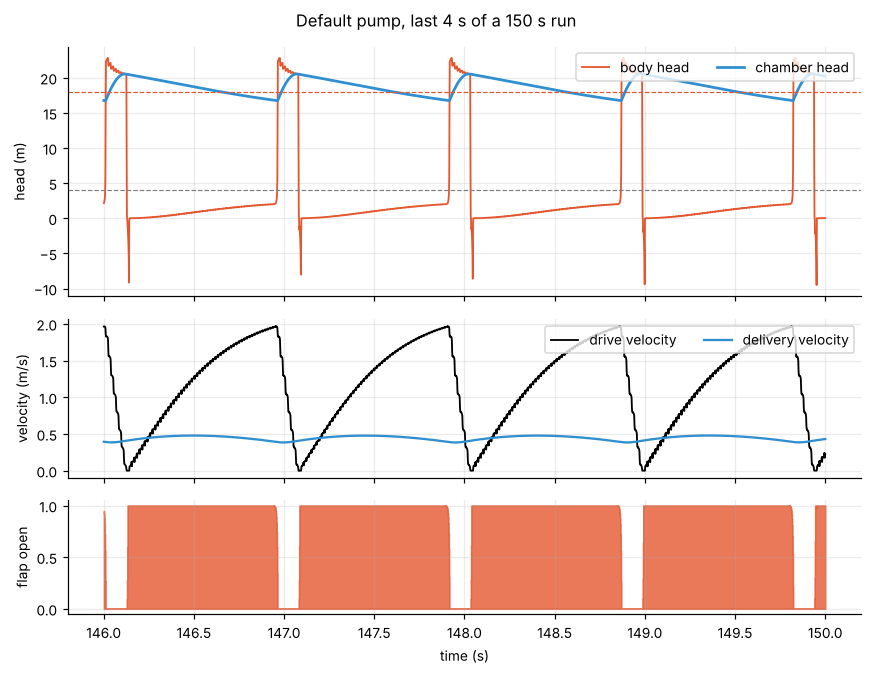

In [4]:
import time
t0 = time.time()
pump, tr = run(150, record_last=4.0)
print("ran %.0f s of pump time in %.1f s of computer time" % (pump.t, time.time() - t0))
print("beats:", pump.beats, "  beat rate: %.1f per minute" % (60 * 12 / (pump.beat_times[-1] - pump.beat_times[-13])))
t, Hb, Hch, V, vd, flap, _, Qd = tr.T
fig, ax = plt.subplots(3, 1, figsize=(8, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.4, 1]})
ax[0].plot(t, Hb, color="#E4572E", lw=1.2, label="body head"); ax[0].plot(t, Hch, color="#2F8FD0", lw=1.8, label="chamber head")
ax[0].axhline(4, ls="--", c="gray", lw=.8); ax[0].axhline(18, ls="--", c="#E4572E", lw=.8); ax[0].set_ylabel("head (m)"); ax[0].legend(loc="upper right", ncol=2)
ax[1].plot(t, V, color="k", lw=1.2, label="drive velocity"); ax[1].plot(t, vd, color="#2F8FD0", lw=1.5, label="delivery velocity"); ax[1].set_ylabel("velocity (m/s)"); ax[1].legend(loc="upper right", ncol=2)
ax[2].fill_between(t, flap, color="#E4572E", alpha=.8, step="mid"); ax[2].set_ylabel("flap open"); ax[2].set_xlabel("time (s)")
fig.suptitle("Default pump, last 4 s of a 150 s run"); fig.tight_layout(); plt.show()

## 3. Check: the water balance

Every cubic metre that enters at the intake must leave at the waste valve, sit in the air chamber, fill the delivery pipe or reach the tank. Two of the three residuals are zero to rounding. The third is the water squeezed into the elastic drive pipe.

In [5]:
b = pump.balance()
rows = [("Drawn from the intake", b["intake"]), ("Passed the supply valve", b["drive"]), ("  wasted at the waste valve", b["waste"]),
        ("  pushed through the check valve", b["pump"]), ("    stored in the air chamber", b["stored"]),
        ("    filling the delivery pipe", b["column"]), ("    delivered to the tank", b["delivered"])]
for n, v in rows: print("%-34s %9.3f L  %5.1f %%" % (n, v * 1e3, 100 * v / b["intake"]))
print()
print("drive - waste - pumped              = %+.2e m3" % b["res_body"])
print("pumped - stored - filling - tank    = %+.2e m3" % b["res_delivery"])
print("intake - drive (pipe compressibility)= %+.2e m3  (%.4f %% of the intake)" % (b["res_pipe"], 100 * b["res_pipe"] / b["intake"]))
print("D'Aubuisson efficiency, whole run    = %.3f" % b["eta"])
assert abs(b["res_body"]) < 1e-12 and abs(b["res_delivery"]) < 1e-12 and abs(b["res_pipe"]) < 1e-4 * b["intake"]
assert b["delivered"] * pump.p["h"] <= b["drive"] * pump.p["Hs"], "energy out exceeds energy in"
print("balance and energy checks passed")

Drawn from the intake                352.705 L  100.0 %
Passed the supply valve              352.706 L  100.0 %
  wasted at the waste valve          308.044 L   87.3 %
  pushed through the check valve      44.662 L   12.7 %
    stored in the air chamber          2.380 L    0.7 %
    filling the delivery pipe         24.396 L    6.9 %
    delivered to the tank             17.885 L    5.1 %

drive - waste - pumped              = +2.57e-15 m3
pumped - stored - filling - tank    = +1.80e-16 m3
intake - drive (pipe compressibility)= -1.97e-07 m3  (-0.0001 % of the intake)
D'Aubuisson efficiency, whole run    = 0.228
balance and energy checks passed


## 4. Check: Joukowsky pressure rise

Hold the waste valve open with a huge preload, let a steady flow settle, then close the supply valve in 2 ms. For a closure much faster than `2L/a` the pressure at the valve rises by `a V / g` above its steady value.

In [6]:
j = Ram(Hs=20, L=100, D=0.05, ds=0.1, stroke=0.05, vratio=200, dc=0.002, Vch=0.001, valveTime=0.5)
j.phi_target = 1.0
for _ in range(round(20 / j.dt)): j.step()
V0 = j.Q[j.N] / j.A; H0 = j.H[j.N]
j.p["valveTime"] = 0.002; j.phi_target = 0.0
peak = -1e9
for _ in range(round(0.4 / j.dt)):
    j.step(); peak = max(peak, j.H[j.N])
expected = H0 + j.a * V0 / G
print("steady velocity V0 = %.3f m/s, pipe-end head H0 = %.2f m, wave speed a = %.1f m/s" % (V0, H0, j.a))
print("expected peak  H0 + aV/g = %.1f m" % expected)
print("computed peak            = %.1f m   (%.1f %% difference)" % (peak, 100 * (peak - expected) / expected))
assert abs(peak - expected) < 0.06 * expected

steady velocity V0 = 2.656 m/s, pipe-end head H0 = 0.13 m, wave speed a = 1378.9 m/s
expected peak  H0 + aV/g = 373.5 m
computed peak            = 392.1 m   (5.0 % difference)


## 5. Check: steady flow against the energy equation

With the flap held open the supply head is spent on the entrance loss, the open valve, pipe friction and the waste orifice:

`Hs = ( 0.5 + 0.2 + f L / D + (A / (Cd A_gap))² ) V² / 2g`

Friction factor `f` depends on `V`, so the analytic value is found by iteration, independently of the solver.

In [7]:
cfg = dict(Hs=10, L=40, D=0.05, ds=0.08, stroke=0.05, vratio=200, dc=0.001, Vch=0.001, valveTime=0.2)
k = Ram(**cfg); k.phi_target = 1.0
for _ in range(round(30 / k.dt)): k.step()
V_sim = k.Q[k.N] / k.A
Agap = min(math.pi * cfg["ds"] * k.y, k.As)
V = 1.0
for _ in range(60):                                   # fixed-point iteration on V
    K = 0.5 + 0.2 + fric(V, cfg["D"], k.eps) * cfg["L"] / cfg["D"] + (k.A / (CD_W * Agap)) ** 2
    V = math.sqrt(2 * G * cfg["Hs"] / K)
print("solver V = %.4f m/s   analytic V = %.4f m/s   difference %.2f %%" % (V_sim, V, 100 * (V_sim - V) / V))
assert abs(V_sim - V) < 0.02 * V

solver V = 2.9278 m/s   analytic V = 2.9278 m/s   difference 0.00 %


## 6. Check: hoop stress and burst head

`σ = ρ g H (D + t) / 2t`. The burst head is the head where σ reaches the tensile strength. For the same 50 mm pipe with a 3 mm wall the materials differ enormously. The plot shows why a thin plastic pipe is the first thing to fail.

steel      strength   360 MPa   burst head    4154 m  (40.8 MPa pressure)
ductile    strength   420 MPa   burst head    4847 m  (47.5 MPa pressure)
castiron   strength   200 MPa   burst head    2308 m  (22.6 MPa pressure)
copper     strength   220 MPa   burst head    2539 m  (24.9 MPa pressure)
bronze     strength   260 MPa   burst head    3000 m  (29.4 MPa pressure)
aluminium  strength   200 MPa   burst head    2308 m  (22.6 MPa pressure)
pvc        strength    50 MPa   burst head     577 m  (5.7 MPa pressure)
hdpe       strength    22 MPa   burst head     254 m  (2.5 MPa pressure)


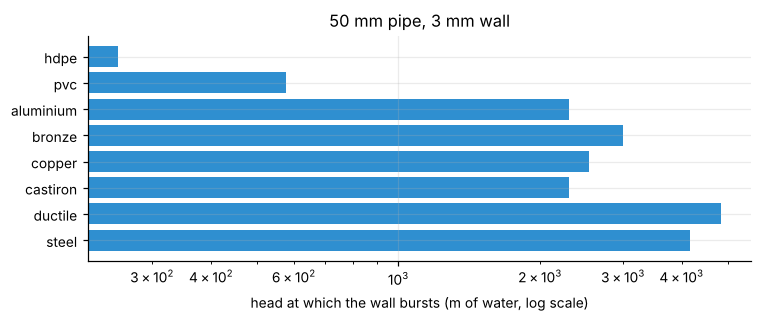

In [8]:
D, t = 0.05, 0.003
names = list(MATERIALS)
heads = [burst_head(m, D, t) for m in names]
for m, h in zip(names, heads):
    assert abs(hoop(h, D, t) - MATERIALS[m]["Su"]) < 1e-6 * MATERIALS[m]["Su"]
    print("%-10s strength %5.0f MPa   burst head %7.0f m  (%.1f MPa pressure)" % (m, MATERIALS[m]["Su"] / 1e6, h, RHO * G * h / 1e6))
fig, ax = plt.subplots(figsize=(7, 3)); ax.barh(names, heads, color="#2F8FD0"); ax.set_xscale("log")
ax.set_xlabel("head at which the wall bursts (m of water, log scale)"); ax.set_title("50 mm pipe, 3 mm wall"); fig.tight_layout(); plt.show()

## 7. Cross-check against the JavaScript solver

`node tools/export-run.js` runs the JavaScript solver for 120 s on two designs and writes the state every 0.5 s. The Python solver above takes exactly the same time steps. The two programs are written independently, so they are not bit-identical (pressure spikes sampled at one instant can differ), but the integrated quantities - water volumes, front position, beat count - agree to a fraction of a percent.

In [9]:
def load(name):
    with open(DATA / ("js_%s_run.csv" % name)) as f:
        return {k: np.array([float(r[k]) for r in csv.DictReader(open(DATA / ("js_%s_run.csv" % name)))]) for k in next(csv.reader(f))}

CASES = {"village": {}, "tall": dict(Hs=5, L=25, D=.075, e=.004, ds=.075, stroke=.0112, vratio=.8, dc=.04, Vch=.01, Dch=.15,
                                       Dd=.032, ed=.0029, Ld=150, h=60)}
worst = {}
for name, cfg in CASES.items():
    js = load(name); py = Ram(**cfg); py.phi_target = 1.0
    want = set(js["step"].astype(int)); mine = {k: [] for k in ("Hb", "Hch", "x", "V_delivered", "V_drive", "V_waste", "beats")}
    for i in range(1, int(js["step"][-1]) + 1):
        py.step()
        if i in want:
            mine["Hb"].append(py.Hb); mine["Hch"].append(py.Hch); mine["x"].append(py.x); mine["V_delivered"].append(py.V["delivered"])
            mine["V_drive"].append(py.V["drive"]); mine["V_waste"].append(py.V["waste"]); mine["beats"].append(py.beats)
    for key, vals in mine.items():
        if key in ("Hb", "Hch"):
            # instantaneous pressures swing by tens of metres inside one step, so compare the cycle maxima instead
            err = abs(np.max(vals) - np.max(js[key])) / np.max(js[key])
        else:
            err = np.max(np.abs(np.array(vals) - js[key])) / (np.max(np.abs(js[key])) + 1e-9)   # relative to the final value
        worst[(name, key)] = err
    print("%-8s %d samples, final beats js %d / python %d, delivered js %.5f L / python %.5f L"
          % (name, len(js["step"]), js["beats"][-1], py.beats, js["V_delivered"][-1] * 1e3, py.V["delivered"] * 1e3))
print()
for (n, k), e in worst.items(): print("%-8s %-12s max difference %.2f %% of full scale" % (n, k, 100 * e))
assert max(worst.values()) < 0.05, "solvers disagree by more than 5 %"
print("\nthe two solvers agree")

village  239 samples, final beats js 117 / python 117, delivered js 11.23681 L / python 11.23928 L
tall     240 samples, final beats js 60 / python 60, delivered js 0.00000 L / python 0.00000 L

village  Hb           max difference 0.77 % of full scale
village  Hch          max difference 0.03 % of full scale
village  x            max difference 0.01 % of full scale
village  V_delivered  max difference 0.12 % of full scale
village  V_drive      max difference 0.01 % of full scale
village  V_waste      max difference 0.01 % of full scale
village  beats        max difference 0.85 % of full scale
tall     Hb           max difference 3.68 % of full scale
tall     Hch          max difference 0.49 % of full scale
tall     x            max difference 0.04 % of full scale
tall     V_delivered  max difference 0.00 % of full scale
tall     V_drive      max difference 0.13 % of full scale
tall     V_waste      max difference 0.16 % of full scale
tall     beats        max difference 1.67 % of full

## 8. Design study: delivered flow against lift

Same pump, same supply head, different delivery height. The delivered flow falls roughly in proportion to the lift ratio, and efficiency stays near 0.3 to 0.5 until the lift gets too high for the pump to keep up. The flows are averaged over the last 60 s of a 150 s run.

lift   6 m : delivered  26.59 L/min   wasted  1.80 L/s   efficiency 0.30
lift  10 m : delivered  20.26 L/min   wasted  1.95 L/s   efficiency 0.37
lift  14 m : delivered  16.04 L/min   wasted  2.06 L/s   efficiency 0.40
lift  18 m : delivered  11.33 L/min   wasted  2.13 L/s   efficiency 0.36
lift  24 m : delivered   3.23 L/min   wasted  2.19 L/s   efficiency 0.14
lift  32 m : delivered   0.00 L/min   wasted  2.19 L/s   efficiency 0.00
lift  44 m : delivered   0.00 L/min   wasted  2.19 L/s   efficiency 0.00


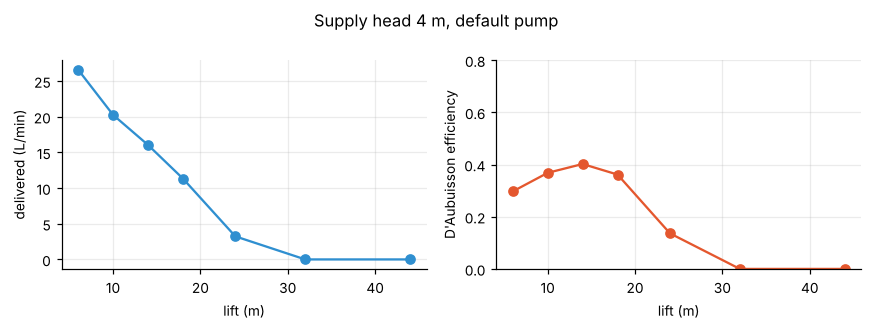

In [10]:
lifts = [6, 10, 14, 18, 24, 32, 44]
rows = []
for h in lifts:
    p, _ = run(90, h=h, Ld=max(50, 2.5 * h))
    mid = Ram(h=h, Ld=max(50, 2.5 * h)); mid.phi_target = 1.0
    for _ in range(round(60 / mid.dt)): mid.step()
    a = dict(mid.V)
    for _ in range(round(60 / mid.dt)): mid.step()
    d_del = (mid.V["delivered"] - a["delivered"]) / 60; d_dr = (mid.V["drive"] - a["drive"]) / 60; d_w = (mid.V["waste"] - a["waste"]) / 60
    rows.append((h, d_del * 60e3, d_w * 1e3, d_del * h / (d_dr * mid.p["Hs"]) if d_dr > 0 else 0))
    print("lift %3d m : delivered %6.2f L/min   wasted %5.2f L/s   efficiency %.2f" % rows[-1])
h_, q_, w_, e_ = map(np.array, zip(*rows))
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
ax[0].plot(h_, q_, "o-", color="#2F8FD0"); ax[0].set_xlabel("lift (m)"); ax[0].set_ylabel("delivered (L/min)")
ax[1].plot(h_, e_, "o-", color="#E4572E"); ax[1].set_xlabel("lift (m)"); ax[1].set_ylabel("D'Aubuisson efficiency"); ax[1].set_ylim(0, 0.8)
fig.suptitle("Supply head 4 m, default pump"); fig.tight_layout(); plt.show()

## Notes

* The failure and leak branches of the solver (bursting parts) live in `src/physics.js` and are covered by `tests/physics.test.js`. This notebook checks the stress formula and the intact pump.
* To explore a different pump change the keyword arguments of `Ram(...)` or `run(...)`. The names match the input boxes of the web app (`Hs`, `L`, `D`, `ds`, `stroke`, `vratio`, `dc`, `Vch`, `Dd`, `Ld`, `h`, ...).
* If you edit `src/physics.js`, run `node tools/export-run.js` again and re-run section 7. A mismatch means the two solvers no longer agree.